# Act 2 · A Hall effect without magnetisation
*Slides [15–22](https://yaroslav-zhumagulov.github.io/demos/nm4qm-2026/slides/#a2)*

MnTe is an antiferromagnet: the moments of its two Mn sublattices cancel. Still, it shows an anomalous Hall effect
(Gonzalez Betancourt et al. 2023). The reason: the two sublattices are related by a rotation, not by a translation,
so MnTe is an altermagnet, with spin-split bands even without spin–orbit coupling. Three questions for this notebook:

1. Can one Wannierisation give both spin channels?
2. For which directions of the Néel vector is σ<sub>xy</sub> allowed?
3. How large is it, and how does it change when the Néel vector turns?

About 4 minutes of compute on 8 cores. **Before you start**, in this folder (about 45 s):
```
python 1_dft.py
```
As in Act 1: each step has a **checkpoint**, **Try it** cells take seconds, the last step is a **bonus**.

In [1]:
import io
import inspect
import logging
import os
import sys
import warnings
from contextlib import redirect_stdout

import matplotlib.pyplot as plt
import numpy as np
from gpaw import GPAW
import gpaw.old.atomrotations
from irrep.spacegroup import SpaceGroup

import wannierberri as wb
from wannierberri.parallel import ray_init
from wannierberri.smoother import FermiDiracSmoother
from wannierberri.symmetry.projections import Projection, ProjectionsSet

if "altermagnetic" not in inspect.signature(wb.WannierDataSOC.from_gpaw).parameters:
    raise ImportError(f"this kernel ({sys.prefix}) has WannierBerri {wb.__version__}, the notebook needs 26.10 "
                      "or newer: run  bash setup/setup.sh  or switch the kernel")

sys.modules["gpaw.atomrotations"] = gpaw.old.atomrotations  # irrep 3.3 looks for it where GPAW 25 had it

warnings.simplefilter("ignore")  # keep the live output readable
logging.basicConfig(level=logging.WARNING, format="%(message)s", stream=sys.stdout)
logging.getLogger("wannierberri").setLevel(logging.ERROR)  # its warnings would flood the output,
logging.getLogger("wannierberri.wannierisation").setLevel(logging.INFO)  # but show the Wannierisation progress
os.makedirs("wannier", exist_ok=True)
os.makedirs("results", exist_ok=True)
np.random.seed(0)  # the Wannierisation draws random numbers: fix them for reproducible output

## Step 1 · Symmetry of one spin channel
*Slides [16–17](https://yaroslav-zhumagulov.github.io/demos/nm4qm-2026/slides/#s11)*

The magnetic moments make Mn1 (↑) and Mn2 (↓) different species, so each spin channel
only has the 12 operations that keep the sublattices: $P\bar 3m1$.
The operations that swap them (a 60° turn about $c$ with a shift by $c/2$, and the $c$-glide) also flip the spin: that is the altermagnetic symmetry.

**Checkpoint:** moments ≈ ±4.4 μ<sub>B</sub> on Mn, 24 operations (12, doubled by time reversal), 24 irreducible k-points.

In [2]:
calc = GPAW("gpaw/nscf.gpw", txt=None, legacy_gpaw=True)
EF = calc.get_fermi_level()
sg = SpaceGroup.from_gpaw(calc)
print("magnetic moments:", np.round(calc.get_magnetic_moments(), 1) + 0.0)
print(f"spin-channel group {sg.name}: {sg.size} operations (with time reversal)")
print(f"{len(calc.get_ibz_k_points())} irreducible k-points of the 6x6x4 grid (144 points)")

magnetic moments: [ 4.4 -4.4  0.   0. ]
spin-channel group P-3m11': 24 operations (with time reversal)
24 irreducible k-points of the 6x6x4 grid (144 points)


## Step 2 · Wannier functions for spin ↑ only
*Slide [17](https://yaroslav-zhumagulov.github.io/demos/nm4qm-2026/slides/#s12)*

13 functions: Mn1-$d$ and Te $sp^2 + p_z$ (i.e. Te $s+p$). They span all occupied spin-↑ bands
above the Mn semicore states (`IBstart=8`). With `altermagnetic=True` the spin-↓ channel is never Wannierised:
it is generated by the operation that maps Mn1 → Mn2 and flips the spin.

The NSCF grid is the SCF grid, 6×6×4 (24 irreducible points).

**Checkpoint:** after 200 iterations (about 25 s): compact Mn-$d$ functions (spread ≈ 0.5 Å²) and more extended
Te $sp^2$ and $p_z$ functions (≈ 2 and ≈ 3.4 Å²), as expected for localised 3$d$ and diffuse 5$p$ states.

In [3]:
Te = [[1 / 3, 2 / 3, 1 / 4], [2 / 3, 1 / 3, 3 / 4]]
projections = ProjectionsSet([
    Projection(position_num=[0, 0, 0], orbital="d", spacegroup=sg),
    Projection(position_num=Te, orbital="sp2", spacegroup=sg, xaxis=[0, -1, 0], rotate_basis=True),
    Projection(position_num=Te, orbital="pz", spacegroup=sg),
])
wandata = wb.WannierDataSOC.from_gpaw(calc, projections=projections, altermagnetic=True,
                                      IBstart=8, seedname="wannier/mnte")
wandata.wannierise(froz_min=-np.inf, froz_max=EF + 0.1, num_iter=200,
                   print_progress_every=100, sitesym=True)

mpgrid = [6 6 4], 24
mpgrid = [6 6 4], 24


magmom_transformed=array([ 4.41256548e+00, -4.41256551e+00,  4.25603128e-08,  4.25603130e-08]), atommap=array([0, 1, 2, 3]), m-transformed=[ 8.82513095e+00 -8.82513101e+00  8.51206256e-08  8.51206260e-08]
magmom_transformed=array([ 4.41256548e+00, -4.41256551e+00,  4.25603130e-08,  4.25603128e-08]), atommap=array([0, 1, 3, 2]), m-transformed=[ 8.82513095e+00 -8.82513101e+00  8.51206258e-08  8.51206258e-08]
magmom_transformed=array([-4.41256551e+00,  4.41256548e+00,  4.25603130e-08,  4.25603128e-08]), atommap=array([1, 0, 3, 2]), m-transformed=[-3.16997255e-08 -3.16997255e-08  8.51206258e-08  8.51206258e-08]


The check of irreps is not implemented for anti-unitary symmetries. Skipping the check, leaving to your responsibility


Using the Wannier centers from the projections as initial guess


####################################################################################################


...

####################################################################################################


time for creating wannierizer 2.293757200241089


time for iterations 8.883316278457642


time for updating 7.967343807220459


total time for wannierization 11.206506967544556


In [4]:
with redirect_stdout(io.StringIO()):  # irrep prints every symmetry operation here
    system = wb.SystemSOC.from_wannierdata(wandata, berry=True)

## Step 3 · Altermagnetic spin splitting (no SOC)
*Slide [18](https://yaroslav-zhumagulov.github.io/demos/nm4qm-2026/slides/#s13)*

Spin ↑ and ↓ bands are degenerate in the $k_z=0$ plane, but split at $k_z\neq 0$,
with opposite sign for opposite in-plane directions: a $g$-wave altermagnet.

**Checkpoint:** the spins are degenerate on the $k_z = 0$ part of the path and split by up to ≈ 1 eV on the
$k_z = 0.35$ Å⁻¹ part.

max |E_up - E_dn|: 1.0 eV


Text(0.5, 1.0, 'no SOC')

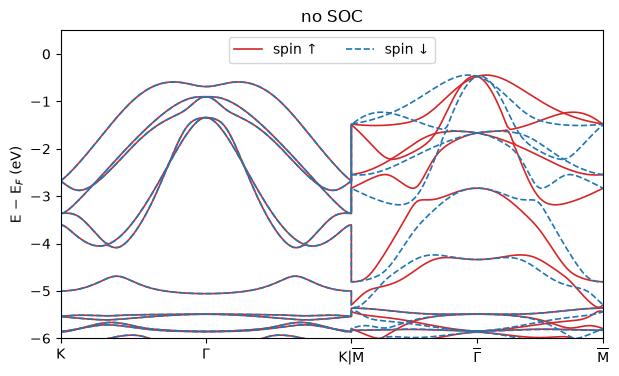

In [5]:
c = system.real_lattice[2, 2]
kz = 0.35 * c / (2 * np.pi)  # k_z = 0.35 1/Angstrom, in reduced units
path = wb.Path.from_nodes(system, nodes=[[2 / 3, -1 / 3, 0], [0, 0, 0], [-2 / 3, 1 / 3, 0], None,
                                         [-1 / 2, 0, kz], [0, 0, kz], [1 / 2, 0, kz]],
                          labels=["K", "Γ", "K", r"$\overline{\mathrm{M}}$", r"$\overline{\Gamma}$", r"$\overline{\mathrm{M}}$"],
                          length=300)   # barred labels: the k_z = 0.35 1/Angstrom plane
E_up = wb.evaluate_k_path(system.system_up, path=path).get_eigenvalues() - EF
E_dn = wb.evaluate_k_path(system.system_down, path=path).get_eigenvalues() - EF
x = path.getKline()
ticks, names = [], []
for i, name in path.labels.items():
    if ticks and np.isclose(x[i], ticks[-1]):
        names[-1] += "|" + name
    else:
        ticks.append(x[i])
        names.append(name)
print(f"max |E_up - E_dn|: {np.abs(E_up - E_dn).max():.1f} eV")

fig, ax = plt.subplots(figsize=(7, 4))
up = ax.plot(x, E_up, color="C3", lw=1.2)
down = ax.plot(x, E_dn, color="C0", lw=1.2, ls="--")
ax.legend([up[0], down[0]], ["spin ↑", "spin ↓"], loc="upper center", ncol=2)   # one entry per spin
ax.set_xticks(ticks, names)
ax.set_xlim(x[0], x[-1])
ax.set_ylim(-6, 0.5)
ax.set_ylabel("E − E$_F$ (eV)")
ax.set_title("no SOC")

## Step 4 · SOC on demand: choose the Néel vector
*Slide [19](https://yaroslav-zhumagulov.github.io/demos/nm4qm-2026/slides/#s14)*

`set_soc_axis(theta, phi)` rotates the spin quantisation axis $\hat{\mathbf n}$ and rebuilds the
magnetic point group used to symmetrise the results. Here $\hat{\mathbf n}\parallel y = [01\bar10]$, perpendicular to $a$.
The colour is the spin along $\hat{\mathbf n}$. In the $k_z = 0$ plane it is zero by symmetry, so those bands stay grey.

**Checkpoint:** SOC raises the highest state on this path by ≈ 0.13 eV.

highest state on this path: -0.45 eV without SOC, -0.32 eV with SOC


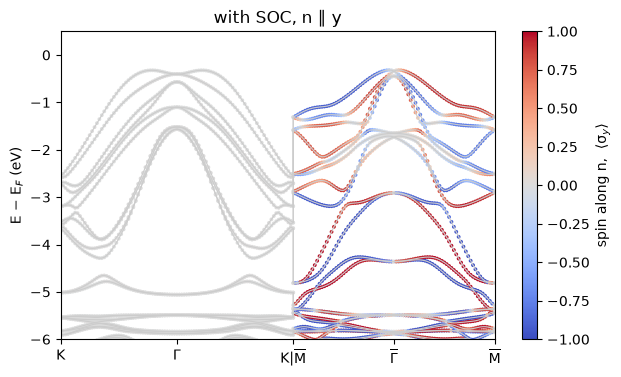

In [6]:
system.set_soc_axis(theta=90, phi=90, units="degrees")
tab = wb.evaluate_k_path(system, path=path, quantities=["spin"])
E_soc, S = tab.get_eigenvalues() - EF, tab.get_data("spin")
print(f"highest state on this path: {E_up.max():.2f} eV without SOC, {E_soc.max():.2f} eV with SOC")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x, E_soc, color="0.8", lw=0.8)
sc = ax.scatter(np.repeat(x, E_soc.shape[1]), E_soc.ravel(), c=S[:, :, 1].ravel(), s=3,
                cmap="coolwarm", vmin=-1, vmax=1)
fig.colorbar(sc, label="spin along n,  ⟨σ$_y$⟩")
ax.set_xticks(ticks, names)
ax.set_xlim(x[0], x[-1])
ax.set_ylim(-6, 0.5)
ax.set_ylabel("E − E$_F$ (eV)")
ax.set_title("with SOC, n ∥ y")
np.savez("results/mnte_bands.npz", x=x, ticks=ticks, labels=names,
         E_up=E_up, E_dn=E_dn, E_soc=E_soc, S=S)

**Check against GPAW.** GPAW's second-variation SOC (all 2 × 40 bands of the collinear run) is the reference for the
model's first-order SOC. It takes seconds.

**Checkpoint:** the model reproduces GPAW's full SOC: ≈ 0.32 eV for n ∥ c, and a 4–5 times smaller shift for n ∥ y.

In [7]:
from gpaw.spinorbit import soc_eigenstates

kibz = calc.get_ibz_k_points()
levels = {"Energy": wb.calculators.tabulate.Energy(degen_thresh=1e-6)}
iA = np.argmin(np.linalg.norm(kibz - [0, 0, 0.5], axis=1))   # the A point
E_A0 = calc.get_eigenvalues(kpt=iA, spin=0)[20]              # top valence level at A without SOC
for name, (theta, phi) in {"n || c": (0, 0), "n || y": (90, 90)}.items():
    system.set_soc_axis(theta=theta, phi=phi, units="degrees")
    E_w = wb.evaluate_k(system, k=kibz[iA], calculators={"E": levels["Energy"]}).data[0].max()
    E_g = np.sort(soc_eigenstates(calc, theta=theta, phi=phi).eigenvalues()[iA])[41]
    print(f"{name}: SOC lifts the top level at A by {(E_w - E_A0) * 1e3:4.0f} meV (model), "
          f"{(E_g - E_A0) * 1e3:4.0f} meV (GPAW)")

n || c: SOC lifts the top level at A by  322 meV (model),  321 meV (GPAW)
n || y: SOC lifts the top level at A by   75 meV (model),   60 meV (GPAW)


**Rotate the Néel vector** from c to y in 10° steps, one `set_soc_axis` call per angle, no new DFT.
We keep the spin component along $\hat{\mathbf n}$ for the plots.

**Checkpoint:** the shift at A falls smoothly, four- to fivefold, as n turns from c into the plane.

In [8]:
thetas = np.arange(0, 91, 10)
E_rot, S_rot, shift_A = [], [], []
for theta in thetas:
    system.set_soc_axis(theta=theta, phi=90, units="degrees")
    n = np.array([0, np.sin(np.deg2rad(theta)), np.cos(np.deg2rad(theta))])   # Neel vector in the y-z plane
    tab = wb.evaluate_k_path(system, path=path, quantities=["spin"])
    E_rot.append(tab.get_eigenvalues() - EF)
    S_rot.append(tab.get_data("spin") @ n)
    E_top = wb.evaluate_k(system, k=kibz[iA], calculators={"E": levels["Energy"]}).data[0].max()
    shift_A.append((E_top - E_A0) * 1e3)
    print(f"theta = {theta:2d} deg from c:  SOC lifts the top level at A by {shift_A[-1]:4.0f} meV")
np.savez("results/mnte_soc_rotation.npz", theta=thetas, x=x, E=np.array(E_rot), S_n=np.array(S_rot),
         shift_A=np.array(shift_A))

theta =  0 deg from c:  SOC lifts the top level at A by  322 meV


theta = 10 deg from c:  SOC lifts the top level at A by  319 meV


theta = 20 deg from c:  SOC lifts the top level at A by  309 meV


theta = 30 deg from c:  SOC lifts the top level at A by  292 meV


theta = 40 deg from c:  SOC lifts the top level at A by  269 meV


theta = 50 deg from c:  SOC lifts the top level at A by  240 meV


theta = 60 deg from c:  SOC lifts the top level at A by  206 meV


theta = 70 deg from c:  SOC lifts the top level at A by  166 meV


theta = 80 deg from c:  SOC lifts the top level at A by  122 meV


theta = 90 deg from c:  SOC lifts the top level at A by   75 meV


**Try it.** Now turn $\hat{\mathbf n}$ inside the basal plane (θ = 90°, φ from the a axis). Does the shift at A
change? Predict, then run.

In [9]:
for phi in (0, 30, 60, 90):
    system.set_soc_axis(theta=90, phi=phi, units="degrees")
    E_top = wb.evaluate_k(system, k=kibz[iA], calculators={"E": levels["Energy"]}).data[0].max()
    print(f"phi = {phi:2d} deg from a:  SOC lifts the top level at A by {(E_top - E_A0) * 1e3:4.0f} meV")

phi =  0 deg from a:  SOC lifts the top level at A by   75 meV
phi = 30 deg from a:  SOC lifts the top level at A by   75 meV
phi = 60 deg from a:  SOC lifts the top level at A by   75 meV
phi = 90 deg from a:  SOC lifts the top level at A by   75 meV


## Step 5 · Anomalous Hall conductivity for three Néel vectors
*Slide [20](https://yaroslav-zhumagulov.github.io/demos/nm4qm-2026/slides/#s15)*

$$\sigma_{xy} = -\frac{e^2}{\hbar}\int\frac{d^3k}{(2\pi)^3}\sum_n f(\varepsilon_{n\mathbf k})\,\Omega^z_n(\mathbf k),
\qquad \Omega^z_n = -2\,\mathrm{Im}\sum_{m\ne n}\frac{\langle n|\partial_{k_x}H|m\rangle\langle m|\partial_{k_y}H|n\rangle}{(\varepsilon_n-\varepsilon_m)^2}$$
Symmetry allows a Hall vector along $c$ only for $\hat{\mathbf n}\parallel y = [01\bar10]$;
for $\hat{\mathbf n}\parallel x = [2\bar1\bar10]$ (the $a$ axis) and $\hat{\mathbf n}\parallel c$ it must vanish.

* Grids (multiples of the 6×6×4 Wannier grid): 96×96×64 for $\hat{\mathbf n}\parallel y$, about 40 s on 8 cores.
  At 150 K it is within ~12 S/cm of a 256×256×170 grid over the whole range (optional checks in `03_checks/`); 48×48×32 is
  4 times faster but its peaks can be off by 50% or more. For $\hat{\mathbf n}\parallel x$ and $\hat{\mathbf n}\parallel c$
  symmetry makes $\sigma_{xy}$ vanish on any grid, so the coarse one (~10 s) shows it.
* `degen_thresh=1e-4`: bands closer than 0.1 meV are treated as one group. Larger thresholds (1 meV and up)
  merge real SOC-split pairs and change the result near the band edge; 10⁻⁵ gives the same numbers as 10⁻⁴.
* Occupation: Fermi–Dirac at 150 K, the temperature of the Hall measurement of Gonzalez Betancourt et al. (2023)
  ($T_N$ = 310 K). The model has the fully ordered moments of the DFT run.
* Hole density from the cumulative DOS in the rigid-band picture, $p(E_F) = [N_{\rm W} - N(E_F)]/V_{\rm cell}$,
  with $N_{\rm W} = 26$ spin orbitals per cell, all filled in the undoped crystal.

**Checkpoint:** σ<sub>xy</sub> = 0 for n ∥ x and n ∥ c, as symmetry demands; tens to hundreds of S/cm for n ∥ y
(about 1 min).

In [10]:
try:
    ray_init(logging_level="error", log_to_driver=False)   # k-points in parallel on all cores, quietly
except ImportError:
    print("Ray is not installed: running in serial, several times slower")
T = 150  # K
Efermi = np.linspace(EF - 1.2, EF + 0.2, 1401)
smoother = FermiDiracSmoother(Efermi, T_Kelvin=T)
calculators = {"ahc": wb.calculators.static.AHC(Efermi=Efermi, degen_thresh=1e-4, smoother=smoother),
               "cumdos": wb.calculators.static.CumDOS(Efermi=Efermi, smoother=smoother)}
directions = {"x": (90, 0), "y": (90, 90), "z": (0, 0)}   # x = [2-1-10] (a), y = [01-10], z = c
grids = {"x": (48, 48, 32), "y": (96, 96, 64), "z": (48, 48, 32)}
sigma, holes, results = {}, {}, {}
volume = abs(np.linalg.det(system.real_lattice)) * 1e-24   # cm^3
for name, (theta, phi) in directions.items():
    system.set_soc_axis(theta=theta, phi=phi, units="degrees")
    result = wb.run(system, grid=wb.Grid(system, NK=grids[name]), calculators=calculators,
                    fout_name="wannier/mnte", print_progress_step_time=60)
    results[name] = result
    sigma[name] = result.results["ahc"].dataSmooth / 100  # S/cm, Hall vector (x, y, z)
    holes[name] = (system.num_wann - result.results["cumdos"].dataSmooth) / volume  # holes per cm^3
    print(f"n || {name}: sigma_xy between {round(sigma[name][:, 2].min())} and {round(sigma[name][:, 2].max())} S/cm")

n || x: sigma_xy between 0 and 0 S/cm


n || y: sigma_xy between -194 and 84 S/cm


n || z: sigma_xy between 0 and 0 S/cm


Where is the valence band top with SOC? It is not at a high-symmetry point: the highest band has several close
maxima, so we search a 24×24×13 grid and zoom into the best six candidates.

**Checkpoint:** the band top lies ≈ 0.31 eV below $E_F$, close to the Γ–A line (about 15 s).

In [11]:
energy = {"Energy": wb.calculators.tabulate.Energy(degen_thresh=1e-6)}


def top_valence(k_red):
    tab = wb.evaluate_k_path(system, path=wb.Path(system, k_list=k_red), tabulators=energy, parallel=False)
    return tab.get_eigenvalues()[:, system.num_wann - 1]


system.set_soc_axis(theta=90, phi=90, units="degrees")
k = np.stack(np.meshgrid(np.arange(24) / 24, np.arange(24) / 24, np.linspace(0, 0.5, 13), indexing="ij"), -1)
k = k.reshape(-1, 3)
E_top = np.concatenate([top_valence(k[i:i + 500]) for i in range(0, len(k), 500)])
Ev, k_v = -np.inf, None
for k0 in k[np.argsort(E_top)[::-1][:6]]:
    step = 1 / 24
    for _ in range(4):
        d = np.stack(np.meshgrid(*[np.linspace(-step, step, 7)] * 3, indexing="ij"), -1).reshape(-1, 3)
        E0 = top_valence(k0 + d)
        k0, step = k0 + d[E0.argmax()], step / 3
    if E0.max() - EF > Ev:
        Ev, k_v = E0.max() - EF, k0
k_v = (k_v - [*np.round(k_v[:2]), 0]) @ system.recip_lattice        # Cartesian, in-plane part next to Gamma
print(f"valence band top with SOC, n || y: {Ev:+.2f} eV from E_F, at k_z = {k_v[2]:.2f} 1/A, "
      f"{np.hypot(*k_v[:2]):.2f} 1/A from the Gamma-A line")

valence band top with SOC, n || y: -0.31 eV from E_F, at k_z = 0.38 1/A, 0.03 1/A from the Gamma-A line


For comparison: the films of Gonzalez Betancourt et al. have $p \approx 5\cdot10^{18}$ cm⁻³. At 150 K this puts $E_F$ about
10 meV above the band top (the Fermi tail still leaves holes), where $\sigma_{xy}$ is below 1 S/cm; they estimated
~1 S/cm from DFT on a 400³ grid.

**Checkpoint:** for n ∥ y, σ<sub>xy</sub> peaks at ≈ 80 S/cm about 0.2 eV below the band top and changes sign
about 0.5 eV below it.

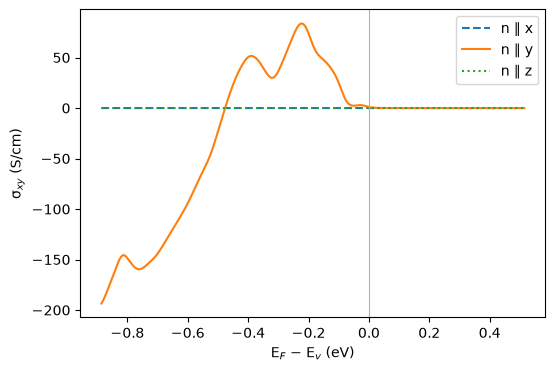

In [12]:
E_rel = Efermi - EF - Ev   # E_F - E_v
fig, ax = plt.subplots(figsize=(6, 4))
for name, ls in zip(directions, ("--", "-", ":")):   # x and z both give zero: dashed and dotted
    ax.plot(E_rel, sigma[name][:, 2], ls=ls, label=f"n ∥ {name}")
ax.axvline(0, color="0.7", lw=0.8)
ax.set_xlabel("E$_F$ − E$_v$ (eV)")
ax.set_ylabel("σ$_{xy}$ (S/cm)")
ax.legend()
np.savez("results/mnte_ahc.npz", E=Efermi - EF, Ev=Ev, T=T, **{f"sigma_{k}": v for k, v in sigma.items()},
         **{f"holes_{k}": v for k, v in holes.items()}, **{f"NK_{k}": v for k, v in grids.items()})

**Try it.** Temperature only changes the occupation, so the n ∥ y result can be re-smoothed without new k-points.
How much does 300 K change σ<sub>xy</sub>, and what does the unsmoothed (T = 0) curve look like?

In [13]:
raw = results["y"].results["ahc"].data[:, 2] / 100          # T = 0, S/cm
i4 = np.argmin(np.abs(E_rel + 0.4))                         # E_F = E_v - 0.4 eV
for T_try in (0, 150, 300):
    s_T = FermiDiracSmoother(Efermi, T_Kelvin=T_try)(raw) if T_try else raw
    print(f"T = {T_try:3d} K:  sigma_xy(E_v - 0.4 eV) = {s_T[i4]:4.0f} S/cm,  "
          f"largest |sigma_xy| = {np.abs(s_T).max():4.0f} S/cm")

T =   0 K:  sigma_xy(E_v - 0.4 eV) =   61 S/cm,  largest |sigma_xy| =  222 S/cm
T = 150 K:  sigma_xy(E_v - 0.4 eV) =   50 S/cm,  largest |sigma_xy| =  194 S/cm
T = 300 K:  sigma_xy(E_v - 0.4 eV) =   41 S/cm,  largest |sigma_xy| =  177 S/cm


## Step 6 · Rotating the Néel vector in the basal plane
*Slides [21–22](https://yaroslav-zhumagulov.github.io/demos/nm4qm-2026/slides/#s16)*

No new DFT: only `set_soc_axis` changes. Symmetry (the 180° turn about a, and the 60° turn about c with a shift by c/2 combined with time reversal) makes
$\sigma_{xy}$ odd in $\varphi$ and antiperiodic with 60°:
$$\sigma_{xy}(-\varphi) = -\sigma_{xy}(\varphi),\qquad \sigma_{xy}(\varphi+60^\circ) = -\sigma_{xy}(\varphi)
\quad\Longrightarrow\quad \sigma_{xy}(\varphi) = A_3\sin 3\varphi + A_9\sin 9\varphi + A_{15}\sin 15\varphi + \dots$$
First the two relations, on the live grid. Each angle is a separate run with its own magnetic point group,
so they test the symmetry of the Wannier model itself.

**Checkpoint:** both relations hold exactly, up to numerical noise far below 1 S/cm (about 35 s).

In [14]:
ahc = {"ahc": calculators["ahc"]}
s = {}
for phi in (10, -10, 70):
    system.set_soc_axis(theta=90, phi=phi, units="degrees")
    s[phi] = wb.run(system, grid=wb.Grid(system, NK=(48, 48, 32)), calculators=ahc,
                    fout_name="wannier/mnte", print_progress_step_time=60).results["ahc"].dataSmooth[:, 2] / 100
# 1e-3 S/cm: far below any physical value, far above the numerical noise of ~1e-7 S/cm
print(f"sigma(-10) = -sigma(10):  {np.allclose(s[-10], -s[10], atol=1e-3)}")
print(f"sigma(70)  = -sigma(10):  {np.allclose(s[70], -s[10], atol=1e-3)}")

sigma(-10) = -sigma(10):  True
sigma(70)  = -sigma(10):  True


Now the amplitudes. The wedge 0°–30° holds all independent information. We read $\sigma_{xy}$ at
$E_F = E_v - 0.7$ eV, deep in the valence band, where this 48×48×32 grid agrees with a 144×144×96 grid to 4% at
every angle (optional checks in `03_checks/`). Closer to the band top, small angles need much denser grids.
About 1 minute on 8 cores.

**Checkpoint:** σ rises much faster than sin 3φ: σ(5°) is already half of σ(30°), where sin 3φ alone would give a
quarter. The fit needs sin 9φ and sin 15φ: σ ≈ A<sub>3</sub> (sin 3φ + 0.18 sin 9φ + 0.04 sin 15φ).

phi =  0.0:  sigma_xy =    0 S/cm


phi =  5.0:  sigma_xy =   81 S/cm


phi = 10.0:  sigma_xy =  113 S/cm


phi = 15.0:  sigma_xy =  136 S/cm


phi = 20.0:  sigma_xy =  148 S/cm


phi = 25.0:  sigma_xy =  149 S/cm


phi = 30.0:  sigma_xy =  144 S/cm
E_F = E_v - 0.7 eV, 6.6e+21 holes/cm^3
sigma(5)/sigma(30) = 0.56; sin 3phi alone gives 0.26
harmonics [3]: A3 = 169 S/cm,  rms residual 22 S/cm
harmonics [3, 9]: A3 = 173 S/cm, A9/A3 = 0.17,  rms residual 7 S/cm
harmonics [3, 9, 15]: A3 = 172 S/cm, A9/A3 = 0.18, A15/A3 = 0.04,  rms residual 5 S/cm


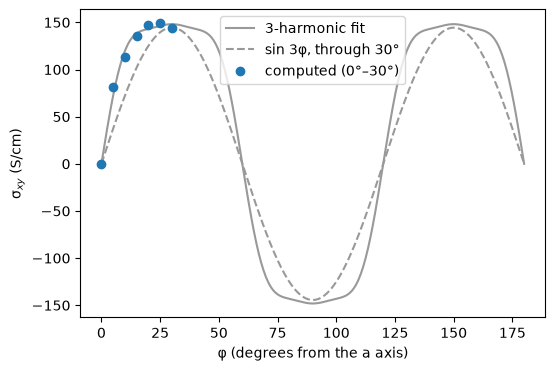

In [15]:
phis = np.arange(0, 30.1, 5)
E0 = Ev - 0.7  # Fermi level in eV, from GPAW's E_F
i0 = np.argmin(np.abs(Efermi - EF - E0))
sigma_phi = []
for phi in phis:
    system.set_soc_axis(theta=90, phi=phi, units="degrees")
    result = wb.run(system, grid=wb.Grid(system, NK=(48, 48, 32)), calculators=ahc,
                    fout_name="wannier/mnte", print_progress_step_time=60)
    sigma_phi.append(result.results["ahc"].dataSmooth[:, 2] / 100)
    print(f"phi = {phi:4.1f}:  sigma_xy = {sigma_phi[-1][i0]:4.0f} S/cm")
sigma_phi = np.array(sigma_phi)
y = sigma_phi[:, i0]
print(f"E_F = E_v - 0.7 eV, {holes['y'][i0]:.1e} holes/cm^3")
print(f"sigma(5)/sigma(30) = {y[1] / y[-1]:.2f}; sin 3phi alone gives {np.sin(np.deg2rad(15)):.2f}")

for ms in ([3], [3, 9], [3, 9, 15]):
    M = np.sin(np.deg2rad(np.outer(phis, ms)))
    coef, *_ = np.linalg.lstsq(M, y, rcond=None)
    rms = np.sqrt(np.mean((M @ coef - y) ** 2))
    ratios = "".join(f", A{m}/A3 = {a / coef[0]:.2f}" for m, a in zip(ms[1:], coef[1:]))
    print(f"harmonics {ms}: A3 = {coef[0]:.0f} S/cm{ratios},  rms residual {rms:.0f} S/cm")

fig, ax = plt.subplots(figsize=(6, 4))
p = np.linspace(0, 180, 361)
ax.plot(p, sum(a * np.sin(np.deg2rad(m * p)) for a, m in zip(coef, [3, 9, 15])), color="0.6",
        label="3-harmonic fit")
ax.plot(p, y[-1] * np.sin(np.deg2rad(3 * p)), color="0.6", ls="--", label="sin 3φ, through 30°")
ax.plot(phis, y, "o", label="computed (0°–30°)")
ax.legend()
ax.set_xlabel("φ (degrees from the a axis)")
ax.set_ylabel("σ$_{xy}$ (S/cm)")
np.savez("results/mnte_neel_scan.npz", phi=phis, E=Efermi - EF, Ev=Ev, sigma=sigma_phi, E0=E0, p_E0=holes["y"][i0])

**Try it.** The two symmetry relations give σ(60° − φ) = σ(φ), so σ(45°) should equal σ(15°) without a new
calculation. Check it (about 10 s).

In [16]:
system.set_soc_axis(theta=90, phi=45, units="degrees")
s45 = wb.run(system, grid=wb.Grid(system, NK=(48, 48, 32)), calculators=ahc,
             fout_name="wannier/mnte", print_progress_step_time=60).results["ahc"].dataSmooth[i0, 2] / 100
print(f"sigma(45 deg) = {s45:.0f} S/cm,  sigma(15 deg) = {y[3]:.0f} S/cm")

sigma(45 deg) = 136 S/cm,  sigma(15 deg) = 136 S/cm


## Bonus 7 · Where the altermagnetic splitting vanishes
*Slides [16](https://yaroslav-zhumagulov.github.io/demos/nm4qm-2026/slides/#s11), [27](https://yaroslav-zhumagulov.github.io/demos/nm4qm-2026/slides/#b2)*

A spin-flipping operation $g$ gives $E_\uparrow(\mathbf k) = E_\downarrow(g\mathbf k)$, so the splitting vanishes on every plane
that $g$ maps onto itself: $k_z = 0$ and $k_z = \pi/c$ (the mirror $m_z$ at $z=\tfrac14$), and the three vertical planes
through Γ–K (the $c$-glides). Four nodal planes make MnTe a $g$-wave altermagnet.
The map shows $E_\uparrow - E_\downarrow$ of the top valence band at $k_z = 0.35$ Å⁻¹ (no SOC).

kz = 0                     plane: E_up = E_dn:  True


kz = pi/c                  plane: E_up = E_dn:  True


vertical, through Gamma-K  plane: E_up = E_dn:  True
Gamma-M line at kz = 0.35 1/A: max |E_up - E_dn| = 1.0 eV


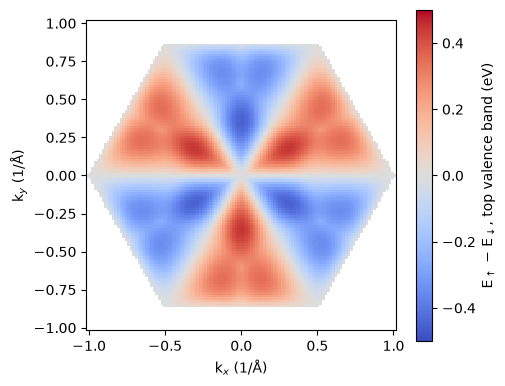

In [17]:
B = system.recip_lattice


def spin_bands(k_cart, batch=400):
    """E_up and E_down of all bands at Cartesian k-points (in batches, to keep memory low)."""
    E_u, E_d = [], []
    for i in range(0, len(k_cart), batch):
        path_k = wb.Path(system, k_list=k_cart[i:i + batch] @ np.linalg.inv(B))
        E_u.append(wb.evaluate_k_path(system.system_up, path=path_k, parallel=False).get_eigenvalues())
        E_d.append(wb.evaluate_k_path(system.system_down, path=path_k, parallel=False).get_eigenvalues())
    return np.concatenate(E_u), np.concatenate(E_d)


def splitting(k_cart):
    """E_up - E_down for all bands at Cartesian k-points."""
    E_u, E_d = spin_bands(k_cart)
    return E_u - E_d


K = np.linalg.norm(B[0] + B[1]) / 3
kx, ky = np.meshgrid(np.linspace(-K, K, 121), np.linspace(-K, K, 121))
edge = K * np.cos(np.pi / 6) / np.cos(np.arctan2(ky, kx) % (np.pi / 3) - np.pi / 6)
inside = np.hypot(kx, ky) <= edge + 1e-9          # hexagonal zone, corners (K points) at 0, 60, ... degrees
dE = splitting(np.stack([kx[inside], ky[inside], np.full(inside.sum(), 0.35)], axis=1))
top = np.full(kx.shape, np.nan)
top[inside] = dE[:, -1]

kzA = np.pi / system.real_lattice[2, 2]       # k_z of the A point
sub = inside & (np.arange(inside.size).reshape(inside.shape) % 3 == 0)
kpar, kperp = np.meshgrid(np.linspace(-K, K, 31), np.linspace(-kzA, kzA, 21))
planes = {"kz = 0": np.stack([kx[sub], ky[sub], np.zeros(sub.sum())], axis=1),
          "kz = pi/c": np.stack([kx[sub], ky[sub], np.full(sub.sum(), kzA)], axis=1),
          "vertical, through Gamma-K": np.stack([kpar.ravel(), np.zeros(kpar.size), kperp.ravel()], axis=1)}
for name, pts in planes.items():
    # 1 ueV: far below any physical splitting, far above the numerical noise of ~1e-14 eV
    print(f"{name:26s} plane: E_up = E_dn:  {np.abs(splitting(pts)).max() < 1e-6}")
k = np.linspace(0, K * np.cos(np.pi / 6), 41)
line = np.stack([k * np.cos(np.pi / 6), k * np.sin(np.pi / 6), np.full_like(k, 0.35)], axis=1)
print(f"Gamma-M line at kz = 0.35 1/A: max |E_up - E_dn| = {np.abs(splitting(line)).max():.1f} eV")

fig, ax = plt.subplots(figsize=(5, 4.3))
im = ax.pcolormesh(kx, ky, top, cmap="coolwarm", vmin=-0.5, vmax=0.5, shading="auto")
fig.colorbar(im, label="E$_\\uparrow$ − E$_\\downarrow$, top valence band (eV)")
ax.set_aspect("equal")
ax.set_xlabel("k$_x$ (1/Å)")
ax.set_ylabel("k$_y$ (1/Å)")
np.savez("results/mnte_splitting_map.npz", kx=kx, ky=ky, top=top, K=K, kz=0.35)

The same map from $k_z = 0$ to $k_z = \pi/c$ in steps of 0.05 Å⁻¹ (about 20 s): the splitting grows from zero,
peaks, and vanishes again on the $k_z = \pi/c$ plane. Both spin bands are saved, for the 3D view on slide 16.

In [18]:
kx_s, ky_s = np.meshgrid(np.linspace(-K, K, 61), np.linspace(-K, K, 61))
edge_s = K * np.cos(np.pi / 6) / np.cos(np.arctan2(ky_s, kx_s) % (np.pi / 3) - np.pi / 6)
inside_s = np.hypot(kx_s, ky_s) <= edge_s + 1e-9
kz_list = np.append(np.arange(0, kzA - 1e-6, 0.05), kzA)
top_up = np.full((len(kz_list),) + kx_s.shape, np.nan)   # top valence band, E - E_F (eV)
top_dn = top_up.copy()
for i, kz in enumerate(kz_list):
    k_cart = np.stack([kx_s[inside_s], ky_s[inside_s], np.full(inside_s.sum(), kz)], axis=1)
    E_u, E_d = spin_bands(k_cart)
    top_up[i][inside_s], top_dn[i][inside_s] = E_u[:, -1] - EF, E_d[:, -1] - EF
    split = np.nanmax(np.abs(top_up[i] - top_dn[i]))
    print(f"kz = {kz:.2f} 1/A: max |E_up - E_dn| of the top band = {split:.2f} eV")
np.savez("results/mnte_splitting_kz.npz", kx=kx_s, ky=ky_s, kz=kz_list, top_up=top_up, top_dn=top_dn, K=K)

kz = 0.00 1/A: max |E_up - E_dn| of the top band = 0.00 eV


kz = 0.05 1/A: max |E_up - E_dn| of the top band = 0.25 eV


kz = 0.10 1/A: max |E_up - E_dn| of the top band = 0.42 eV


kz = 0.15 1/A: max |E_up - E_dn| of the top band = 0.52 eV


kz = 0.20 1/A: max |E_up - E_dn| of the top band = 0.69 eV


...

kz = 0.30 1/A: max |E_up - E_dn| of the top band = 0.60 eV


kz = 0.35 1/A: max |E_up - E_dn| of the top band = 0.45 eV


kz = 0.40 1/A: max |E_up - E_dn| of the top band = 0.29 eV


kz = 0.45 1/A: max |E_up - E_dn| of the top band = 0.14 eV


kz = 0.47 1/A: max |E_up - E_dn| of the top band = 0.00 eV
